<a href="https://colab.research.google.com/github/JavilmIB/Activities/blob/main/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4.- Supervised learning model: Decision tree

**Class:** Artificial Intelligence  
**Professor:** Daniel Isaías López Páez  
**Group:** 001  
**Class time:** Tuesday N4

| Name | Student ID |
|---|---|
| Alejandra Montserrat Hernández Uribe | 1898320 |
| Javier Ivan Lomas Maldonado | 2096554 |
| Adrian Caballero Mena | 2056248 |


## 1. Load libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

## 2. Load data
The *Breast Cancer Wisconsin (Diagnostic)* dataset is included in scikit-learn. It has 569 samples, 30 numeric features computed from digitized images of breast masses, and a target with two classes: malignant (0) and benign (1).

In [ ]:
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target
print("Shape:", df.shape)
print("Classes:", [str(c) for c in cancer.target_names])
df.head()

Shape: (569, 31)
Classes: ['malignant', 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
# Class distribution (0 = malignant, 1 = benign)
print(df['target'].value_counts().rename(index={0: 'malignant', 1: 'benign'}))
print("\nMissing values:", df.isnull().sum().sum())

target
benign       357
malignant    212
Name: count, dtype: int64

Missing values: 0


## 3. Data preprocessing
The data has no missing values, so we only separate features and labels and split them into training (80%) and testing (20%) sets with `train_test_split`. `stratify` keeps the same proportion of malignant/benign in both sets and `random_state` makes the result reproducible.

In [ ]:
X = cancer.data
y = cancer.target

train_data, test_data, train_labels, test_label = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", train_data.shape, train_labels.shape)
print("Testing set: ", test_data.shape, test_label.shape)

Training set: (455, 30) (455,)
Testing set:  (114, 30) (114,)


## 4. Model selection and training
We select a `DecisionTreeClassifier` and train it with the `fit` function using the training data.

In [ ]:
model = DecisionTreeClassifier(random_state=42)
model.fit(train_data, train_labels)
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())

Tree depth: 7
Number of leaves: 19


## 5. Model testing
Predictions are made with the test set, and performance is evaluated with `accuracy_score` and `classification_report`.

In [ ]:
predictions = model.predict(test_data)

accuracy = accuracy_score(test_label, predictions)
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)\n")

print("Classification report:")
print(classification_report(test_label, predictions, target_names=cancer.target_names))

Accuracy: 0.9123 (91.23%)

Classification report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



### Graphical representation of the decision tree (DPI = 300)

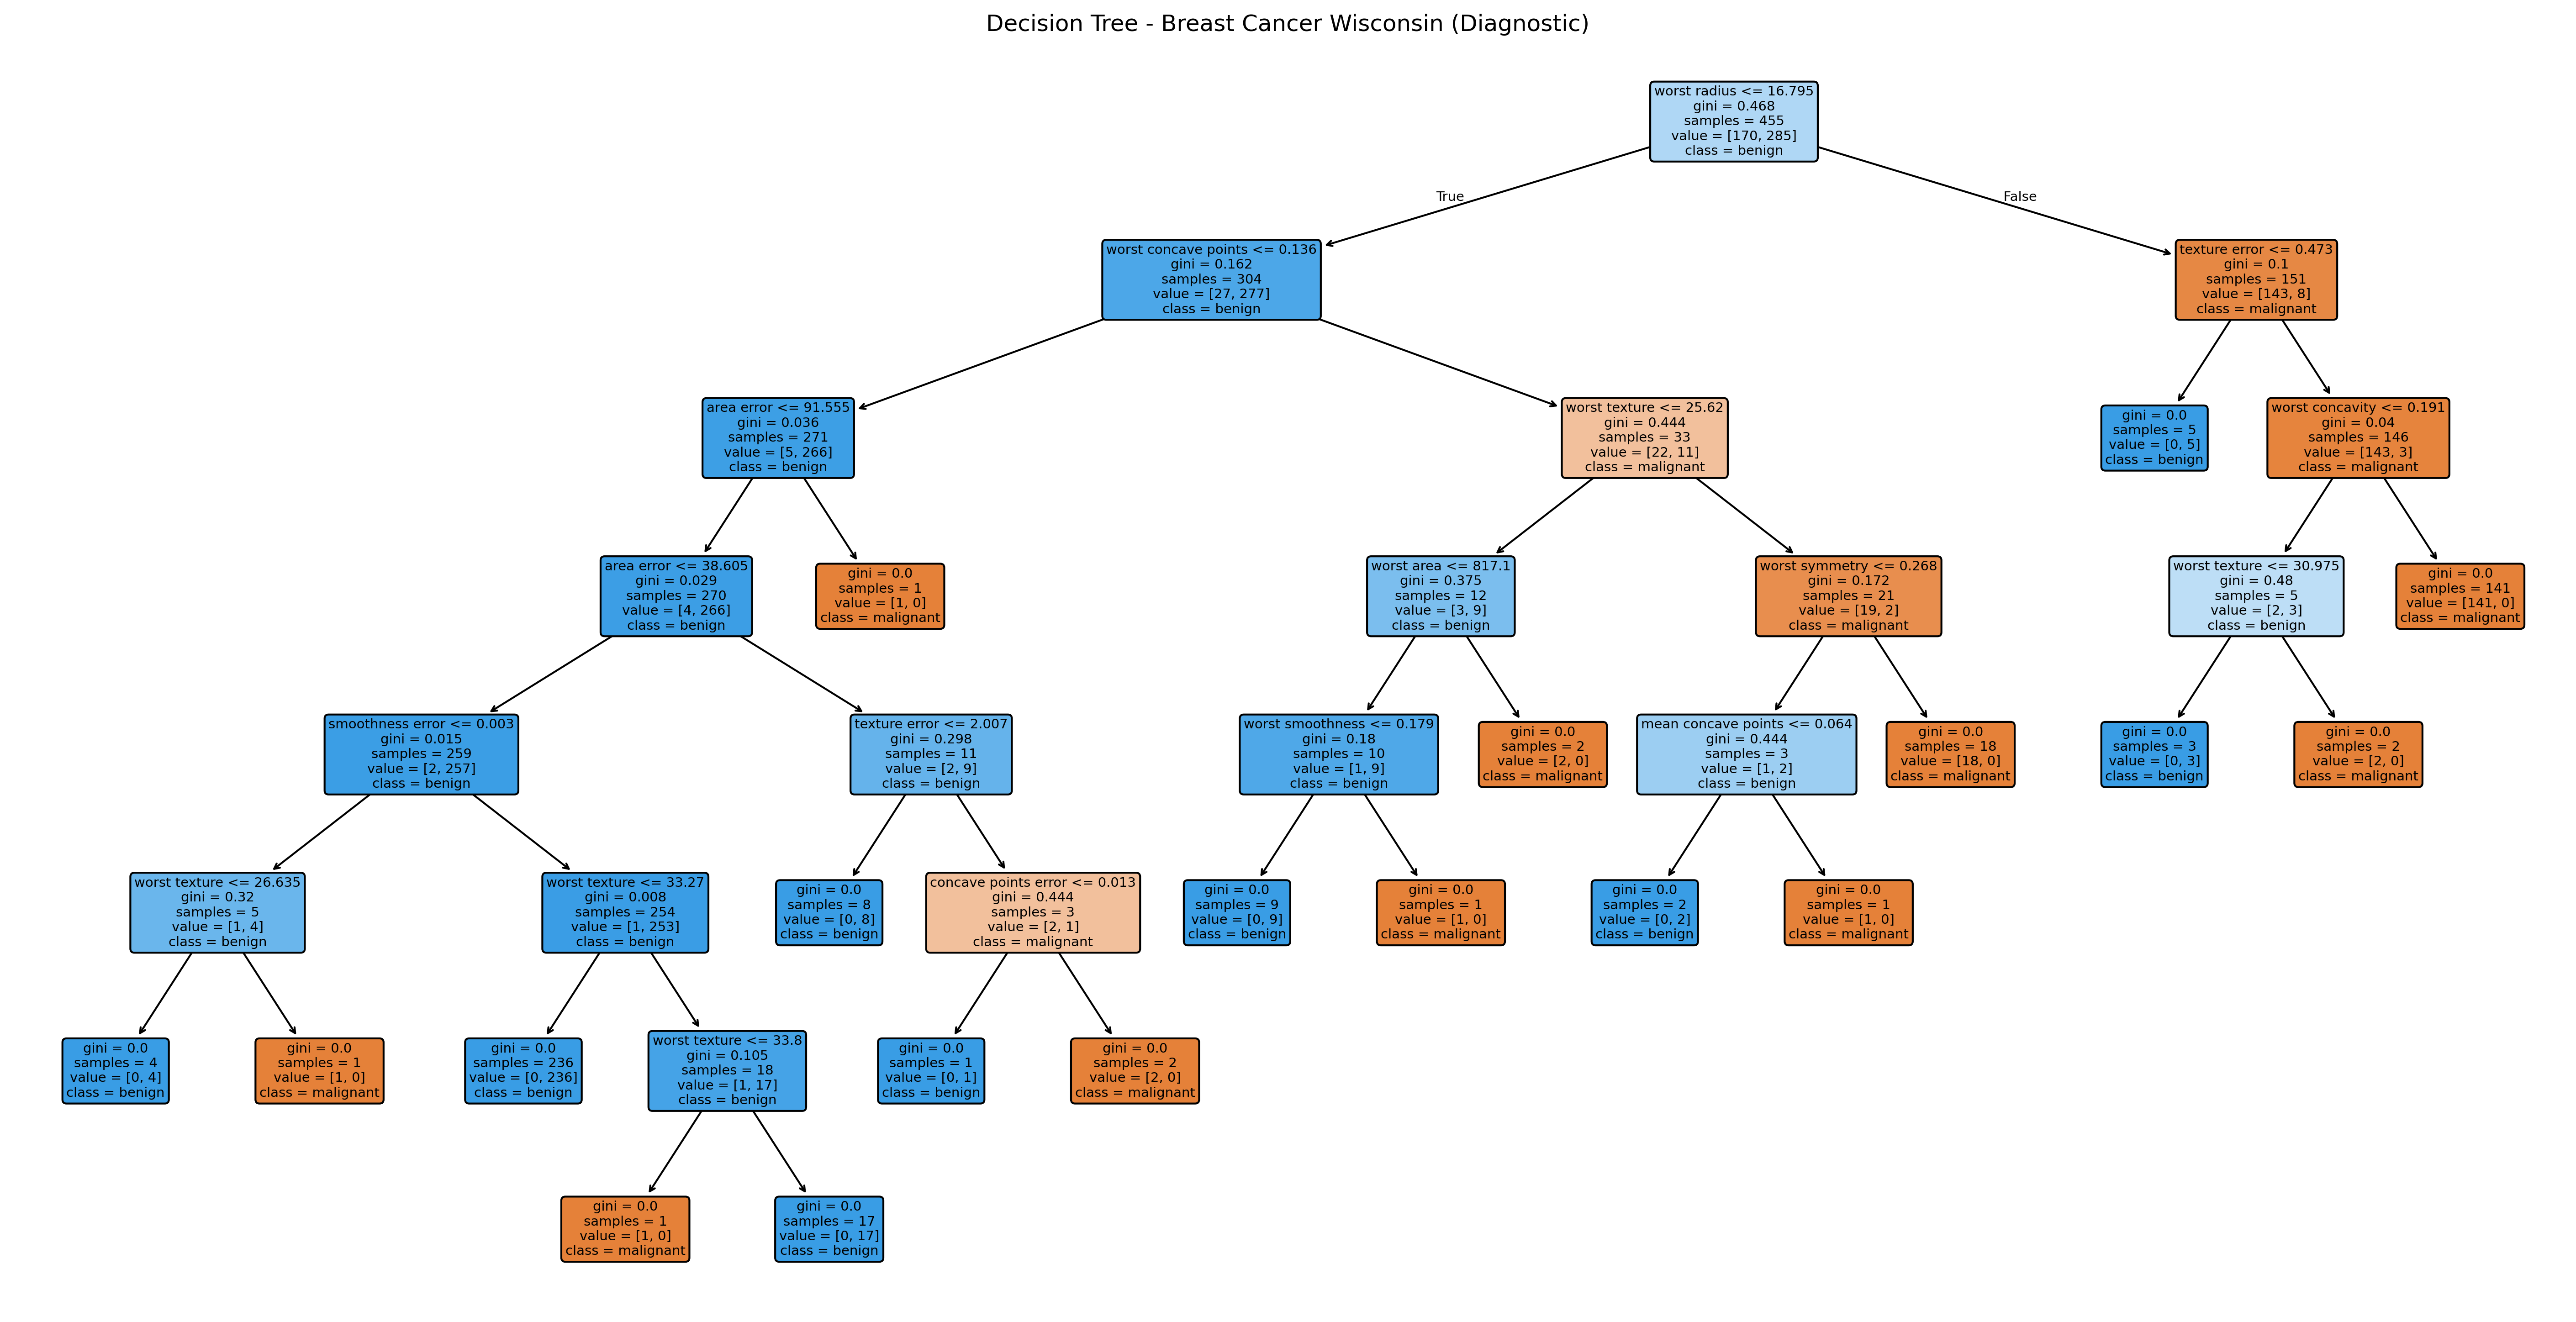

In [ ]:
plt.figure(figsize=(24, 12), dpi=300)
plot_tree(model,
          feature_names=cancer.feature_names,
          class_names=cancer.target_names,
          filled=True, rounded=True, fontsize=7)
plt.title("Decision Tree - Breast Cancer Wisconsin (Diagnostic)")
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()